# TAT-QA (Financial Table & Text QA) — End-to-End JSON & CSV Cleaning Pipeline


---
##  1: Mount Google Drive & Locate TAT-QA Files


In [2]:
from google.colab import drive
import os
import json
import re
import pandas as pd
import numpy as np

# Mount Google Drive
drive.mount('/content/drive')

DRIVE_PROJECT_DIR = '/content/drive/MyDrive/google_colab_project'

# Auto-detect folder location if placed in another directory
if not os.path.exists(DRIVE_PROJECT_DIR):
    print("Searching for TAT-QA dataset across Google Drive...")
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        if any('tatqa' in f.lower() for f in files):
            DRIVE_PROJECT_DIR = root
            print(f"✅ Found TAT-QA folder at: {DRIVE_PROJECT_DIR}")
            break
else:
    print(f"✅ Drive mounted successfully! Working folder: {DRIVE_PROJECT_DIR}")


Mounted at /content/drive
✅ Drive mounted successfully! Working folder: /content/drive/MyDrive/google_colab_project


---
##  2: Configure Environment & Visuals


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("✅ Setup complete! Ready to clean TAT-QA JSON & CSV.")


✅ Setup complete! Ready to clean TAT-QA JSON & CSV.


---



---
##  3: Define Cleaning & Transformation Pipeline Functions


In [3]:
def clean_text(text: str) -> str:
    """Removes non-breaking spaces and irregular unicode artifacts."""
    if not isinstance(text, str):
        return ""
    text = text.replace('\xa0', ' ').replace('\u200b', '').replace('\ufeff', '')
    text = re.sub(r'[ \t]+', ' ', text)
    return text.strip()

def clean_table(table_data):
    """Trims all table cells and standardizes empty strings."""
    if not isinstance(table_data, list):
        return []
    cleaned_rows = []
    for row in table_data:
        if isinstance(row, list):
            cleaned_row = [clean_text(str(cell)) if cell is not None else "" for cell in row]
            cleaned_rows.append(cleaned_row)
    return cleaned_rows

def table_to_markdown(table_matrix):
    """Converts 2D table matrix into clean Markdown format for LLM/RAG pipelines."""
    if not table_matrix or not isinstance(table_matrix, list):
        return ""
    num_cols = max(len(r) for r in table_matrix) if table_matrix else 0
    if num_cols == 0:
        return ""

    norm_matrix = [r + [""] * (num_cols - len(r)) for r in table_matrix]
    header = "| " + " | ".join(norm_matrix[0]) + " |"
    separator = "| " + " | ".join(["---"] * num_cols) + " |"
    rows = [header, separator]
    for r in norm_matrix[1:]:
        rows.append("| " + " | ".join(r) + " |")
    return "\n".join(rows)

print("✅ Pipeline functions ready!")


✅ Pipeline functions ready!


---
##  4: Execute JSON Cleaning & Save Cleaned JSON Files


In [5]:
def clean_and_save_split(split_name, input_json_path, output_json_path):
    if not os.path.exists(input_json_path):
        print(f"⚠️ Input file not found: {input_json_path}")
        return [], [], []

    with open(input_json_path, 'r', encoding='utf-8') as f:
        data = json.load(f)

    cleaned_json_data = []
    qa_records = []
    doc_records = []

    for item in data:
        doc_uid = item.get('table', {}).get('uid', '') or item.get('uid', '')

        # 1. Clean Table
        raw_table = item.get('table', {}).get('table', [])
        cleaned_table = clean_table(raw_table)
        table_rows = len(cleaned_table)
        table_cols = max([len(r) for r in cleaned_table]) if cleaned_table else 0
        table_md = table_to_markdown(cleaned_table)

        # 2. Clean Paragraphs
        raw_paras = item.get('paragraphs', [])
        cleaned_paras = []
        para_texts = []
        for p in raw_paras:
            if isinstance(p, dict):
                p_text = clean_text(p.get('text', ''))
                cleaned_paras.append({
                    'order': p.get('order', 0),
                    'uid': p.get('uid', ''),
                    'date': p.get('date', ''),
                    'text': p_text
                })
                para_texts.append(p_text)
            elif isinstance(p, str):
                cleaned_p = clean_text(p)
                cleaned_paras.append({'text': cleaned_p})
                para_texts.append(cleaned_p)

        combined_paras = "\n\n".join(para_texts)
        context_words = sum(len(t.split()) for t in para_texts)

        # 3. Clean Questions
        raw_questions = item.get('questions', [])
        cleaned_questions = []

        for q in raw_questions:
            q_uid = q.get('uid', '')
            q_text = clean_text(q.get('question', ''))
            q_type = clean_text(str(q.get('answer_type', 'none'))).lower()
            q_scale = clean_text(str(q.get('scale', ''))).lower()
            if not q_scale or q_scale in ['none', 'nan', 'null']:
                q_scale = 'none'

            # Clean Answer
            raw_ans = q.get('answer', [])
            if isinstance(raw_ans, list):
                cleaned_ans = [clean_text(str(a)) for a in raw_ans]
                ans_str = "; ".join(cleaned_ans)
            else:
                cleaned_ans = clean_text(str(raw_ans))
                ans_str = str(cleaned_ans)

            q_derivation = clean_text(str(q.get('derivation', '')))

            cleaned_q = {
                'uid': q_uid,
                'question': q_text,
                'answer': cleaned_ans,
                'answer_type': q_type,
                'derivation': q_derivation,
                'scale': q_scale,
                'facts': q.get('facts', []),
                'mapping': q.get('mapping', {})
            }
            cleaned_questions.append(cleaned_q)

            # Record for CSV
            qa_records.append({
                'question_uid': q_uid,
                'doc_uid': doc_uid,
                'split': split_name,
                'question': q_text,
                'answer': ans_str,
                'answer_type': q_type,
                'derivation': q_derivation,
                'scale': q_scale,
                'question_length_words': len(q_text.split()),
                'has_table': 1 if table_rows > 0 else 0,
                'table_rows': table_rows,
                'table_cols': table_cols,
                'num_paragraphs': len(cleaned_paras),
                'total_context_words': context_words
            })

        doc_records.append({
            'doc_uid': doc_uid,
            'split': split_name,
            'num_paragraphs': len(cleaned_paras),
            'num_questions': len(cleaned_questions),
            'table_rows': table_rows,
            'table_cols': table_cols,
            'table_markdown': table_md,
            'paragraphs_text': combined_paras,
            'total_context_words': context_words
        })

        # Assemble Cleaned JSON item
        cleaned_json_data.append({
            'uid': doc_uid,
            'table': {
                'uid': doc_uid,
                'table': cleaned_table,
                'table_markdown': table_md
            },
            'paragraphs': cleaned_paras,
            'questions': cleaned_questions
        })

    # Save cleaned JSON
    os.makedirs(os.path.dirname(output_json_path), exist_ok=True)
    with open(output_json_path, 'w', encoding='utf-8') as out_f:
        json.dump(cleaned_json_data, out_f, ensure_ascii=False, indent=2)

    print(f"✅ Cleaned JSON split '{split_name}': {len(cleaned_json_data)} docs, {len(qa_records)} QA pairs.")
    print(f"👉 Saved cleaned JSON to: {output_json_path}")
    return cleaned_json_data, qa_records, doc_records

# Locate files and execute cleaning
splits_to_process = [
    ('train', os.path.join(DRIVE_PROJECT_DIR, 'TAT-QA/dataset_raw/tatqa_dataset_train.json'), os.path.join(DRIVE_PROJECT_DIR, 'tatqa_dataset_train_cleaned.json')),
    ('dev', os.path.join(DRIVE_PROJECT_DIR, 'TAT-QA/dataset_raw/tatqa_dataset_dev.json'), os.path.join(DRIVE_PROJECT_DIR, 'tatqa_dataset_dev_cleaned.json')),
    ('test_gold', os.path.join(DRIVE_PROJECT_DIR, 'TAT-QA/dataset_raw/tatqa_dataset_test_gold.json'), os.path.join(DRIVE_PROJECT_DIR, 'tatqa_dataset_test_gold_cleaned.json'))
]

all_qa, all_docs = [], []
for sname, in_path, out_json_path in splits_to_process:
    _, qa, docs = clean_and_save_split(sname, in_path, out_json_path)
    all_qa.extend(qa)
    all_docs.extend(docs)

df_qa = pd.DataFrame(all_qa)
df_docs = pd.DataFrame(all_docs)

print(f"\n🎉 Total Cleaned Questions: {len(df_qa):,}")
print(f"🎉 Total Cleaned Documents: {len(df_docs):,}")
display(df_qa.head(3))


✅ Cleaned JSON split 'train': 2201 docs, 13215 QA pairs.
👉 Saved cleaned JSON to: /content/drive/MyDrive/google_colab_project/tatqa_dataset_train_cleaned.json
✅ Cleaned JSON split 'dev': 278 docs, 1668 QA pairs.
👉 Saved cleaned JSON to: /content/drive/MyDrive/google_colab_project/tatqa_dataset_dev_cleaned.json
✅ Cleaned JSON split 'test_gold': 277 docs, 1663 QA pairs.
👉 Saved cleaned JSON to: /content/drive/MyDrive/google_colab_project/tatqa_dataset_test_gold_cleaned.json

🎉 Total Cleaned Questions: 16,546
🎉 Total Cleaned Documents: 2,756


,question_uid,doc_uid,split,question,answer,answer_type,derivation,scale,question_length_words,has_table,table_rows,table_cols,num_paragraphs,total_context_words
0,9c569bea-e036-4c27-8e41-82c6efab1d31,e78f8b29-6085-43de-b32f-be1a68641be3,train,What does the Weighted average actuarial assum...,Rate of inflation; Rate of increase in salarie...,multi-span,,none,9,1,5,4,4,54
1,83dcc128-9777-4ae2-ba55-50162ac43257,e78f8b29-6085-43de-b32f-be1a68641be3,train,How much is the 2019 rate of inflation?,2.9,span,,percent,8,1,5,4,4,54
2,0384152d-1f9f-4b12-85a9-2ca5e1c97682,e78f8b29-6085-43de-b32f-be1a68641be3,train,How much is the 2018 rate of inflation?,2.9,span,,percent,8,1,5,4,4,54


---
## 📊 Step 5: Visualizations & Benchmark Analytics


/tmp/ipykernel_1092/2499808262.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ans_counts.index, y=ans_counts.values, palette='viridis')


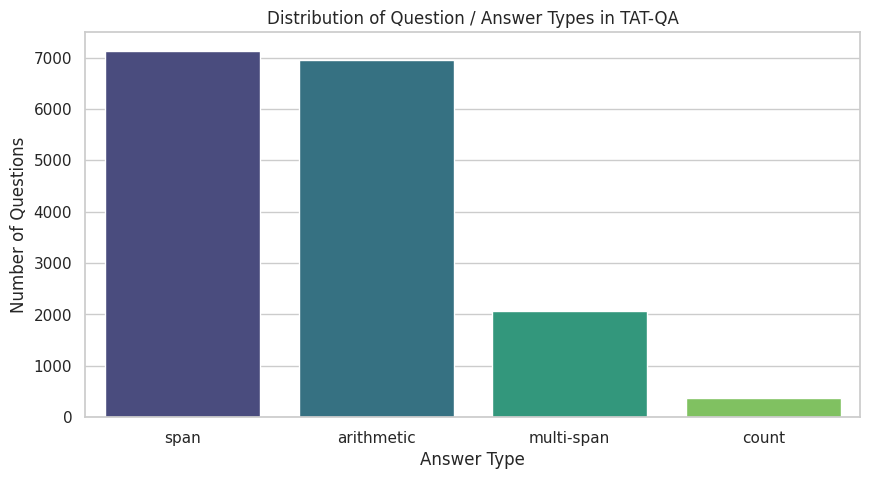

/tmp/ipykernel_1092/2499808262.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=scale_counts.index, y=scale_counts.values, palette='magma')


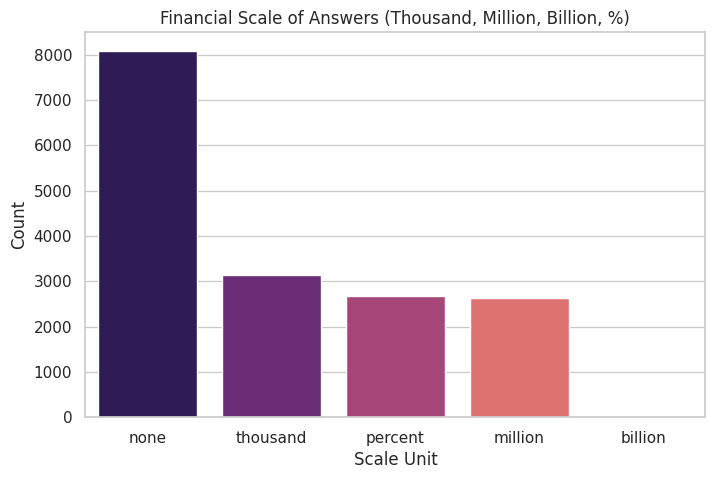

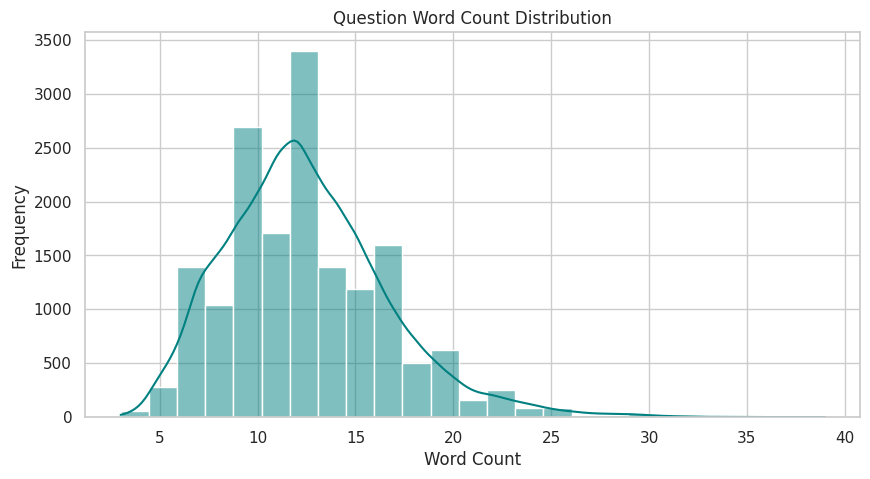

In [6]:
# 1. Answer Type Distribution
plt.figure(figsize=(10, 5))
ans_counts = df_qa['answer_type'].value_counts()
sns.barplot(x=ans_counts.index, y=ans_counts.values, palette='viridis')
plt.title("Distribution of Question / Answer Types in TAT-QA")
plt.xlabel("Answer Type")
plt.ylabel("Number of Questions")
plt.show()

# 2. Scale Distribution (Financial Magnitudes)
plt.figure(figsize=(8, 5))
scale_counts = df_qa['scale'].value_counts()
sns.barplot(x=scale_counts.index, y=scale_counts.values, palette='magma')
plt.title("Financial Scale of Answers (Thousand, Million, Billion, %)")
plt.xlabel("Scale Unit")
plt.ylabel("Count")
plt.show()

# 3. Question Length Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df_qa['question_length_words'], bins=25, kde=True, color='teal')
plt.title("Question Word Count Distribution")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.show()


---
## 💾 Step 6: Export Cleaned CSV Datasets back to Google Drive


In [7]:
qa_export_path = os.path.join(DRIVE_PROJECT_DIR, 'tatqa_qa_cleaned.csv')
docs_export_path = os.path.join(DRIVE_PROJECT_DIR, 'tatqa_documents_cleaned.csv')

df_qa.to_csv(qa_export_path, index=False, encoding='utf-8')
df_docs.to_csv(docs_export_path, index=False, encoding='utf-8')

print("🎉 Successfully exported cleaned files directly to Google Drive:")
print(f"👉 JSON Files: tatqa_dataset_train_cleaned.json, tatqa_dataset_dev_cleaned.json, tatqa_dataset_test_gold_cleaned.json")
print(f"👉 QA CSV: {qa_export_path}")
print(f"👉 Documents CSV: {docs_export_path}")

try:
    from google.colab import files
    print("\nDownloading QA CSV to local machine...")
    files.download(qa_export_path)
except Exception as e:
    print(f"Note: Direct browser download skipped ({e}). Files are stored safely in Google Drive.")


🎉 Successfully exported cleaned files directly to Google Drive:
👉 JSON Files: tatqa_dataset_train_cleaned.json, tatqa_dataset_dev_cleaned.json, tatqa_dataset_test_gold_cleaned.json
👉 QA CSV: /content/drive/MyDrive/google_colab_project/tatqa_qa_cleaned.csv
👉 Documents CSV: /content/drive/MyDrive/google_colab_project/tatqa_documents_cleaned.csv



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>